# Simulation summary visualization

Load the final `summary.csv` and compare the three estimators using MSE only. Each figure fixes the `n2/n1` multiplier; columns are the bias settings (`delta_f = delta_c = delta`), and lines distinguish the estimators.

In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.style.use('seaborn-v0_8-whitegrid')
methods = ['eb', 'ppi_plus_plus_oracle', 'ppi_plus_plus', 'ppi']
method_labels = {'eb': 'EB', 'ppi_plus_plus_oracle': 'PPI++ Oracle', 'ppi_plus_plus': 'PPI++', 'ppi': 'PPI'}


## Plots with common bias in $f(x)$ and $f(\tilde x)$

In [6]:
SUMMARY_PATH = Path('../data/summary_small_n.csv')
if not SUMMARY_PATH.exists():
    candidates = sorted(Path('../results').glob('**/summary.csv'))
    if not candidates:
        raise FileNotFoundError('No summary.csv found. Run combine_results.py first.')
    SUMMARY_PATH = candidates[0]
summary = pd.read_csv(SUMMARY_PATH)

# n2/n1 is the requested multiplier. Keep a rounded value for stable grouping
# when the input contains decimal sample-size multipliers.
summary['multiplier'] = (summary['n2'] / summary['n1']).round(10)

# delta_f and delta_c are intended to be the same bias parameter.
if not np.allclose(summary['delta_f'], summary['delta_c']):
    raise ValueError('Expected delta_f and delta_c to be equal.')
summary['delta'] = summary['delta_f']

multipliers = sorted(summary['multiplier'].unique())
deltas = sorted(summary['delta'].unique())
rhos = sorted(summary['rho'].unique())
summary[['n1', 'n2', 'multiplier', 'delta', 'rho']].head()
summary

,n1,n2,mu,delta_f,delta_c,rho,sigma1,sigma2,sigma3,n_replicates,...,ppi_variance,ppi_mse,ppi_plus_plus_bias,ppi_plus_plus_variance,ppi_plus_plus_mse,ppi_plus_plus_oracle_bias,ppi_plus_plus_oracle_variance,ppi_plus_plus_oracle_mse,multiplier,delta
0,100,100,3.0,0.0,0.0,0.00,1.0,1.0,1.0,10000,...,0.029952,0.029953,-2.087925e-03,0.009991,0.009994,-0.002066,0.009958,0.009961,1.0,0.0
1,100,100,3.0,0.0,0.0,0.25,1.0,1.0,1.0,10000,...,0.024898,0.024899,1.278367e-03,0.009922,0.009922,0.001318,0.009861,0.009862,1.0,0.0
2,100,100,3.0,0.0,0.0,0.50,1.0,1.0,1.0,10000,...,0.019836,0.019834,-4.570080e-04,0.008799,0.008798,-0.000481,0.008737,0.008736,1.0,0.0
3,100,100,3.0,0.0,0.0,0.75,1.0,1.0,1.0,10000,...,0.014940,0.014938,-5.250057e-04,0.007398,0.007398,-0.000577,0.007337,0.007337,1.0,0.0
4,100,100,3.0,0.0,0.0,0.80,1.0,1.0,1.0,10000,...,0.013456,0.013457,-1.271133e-03,0.006718,0.006719,-0.001310,0.006667,0.006668,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
745,1000,50000,3.0,10.0,10.0,0.00,1.0,1.0,1.0,10000,...,0.002036,0.002035,2.797808e-04,0.001005,0.001004,0.000282,0.001003,0.001003,50.0,10.0
746,1000,50000,3.0,10.0,10.0,0.25,1.0,1.0,1.0,10000,...,0.001523,0.001523,1.482318e-07,0.000927,0.000927,0.000002,0.000926,0.000926,50.0,10.0
747,1000,50000,3.0,10.0,10.0,0.50,1.0,1.0,1.0,10000,...,0.000998,0.000998,-1.011989e-04,0.000744,0.000744,-0.000092,0.000742,0.000742,50.0,10.0
748,1000,50000,3.0,10.0,10.0,0.75,1.0,1.0,1.0,10000,...,0.000528,0.000528,-1.549694e-04,0.000458,0.000458,-0.000153,0.000456,0.000456,50.0,10.0


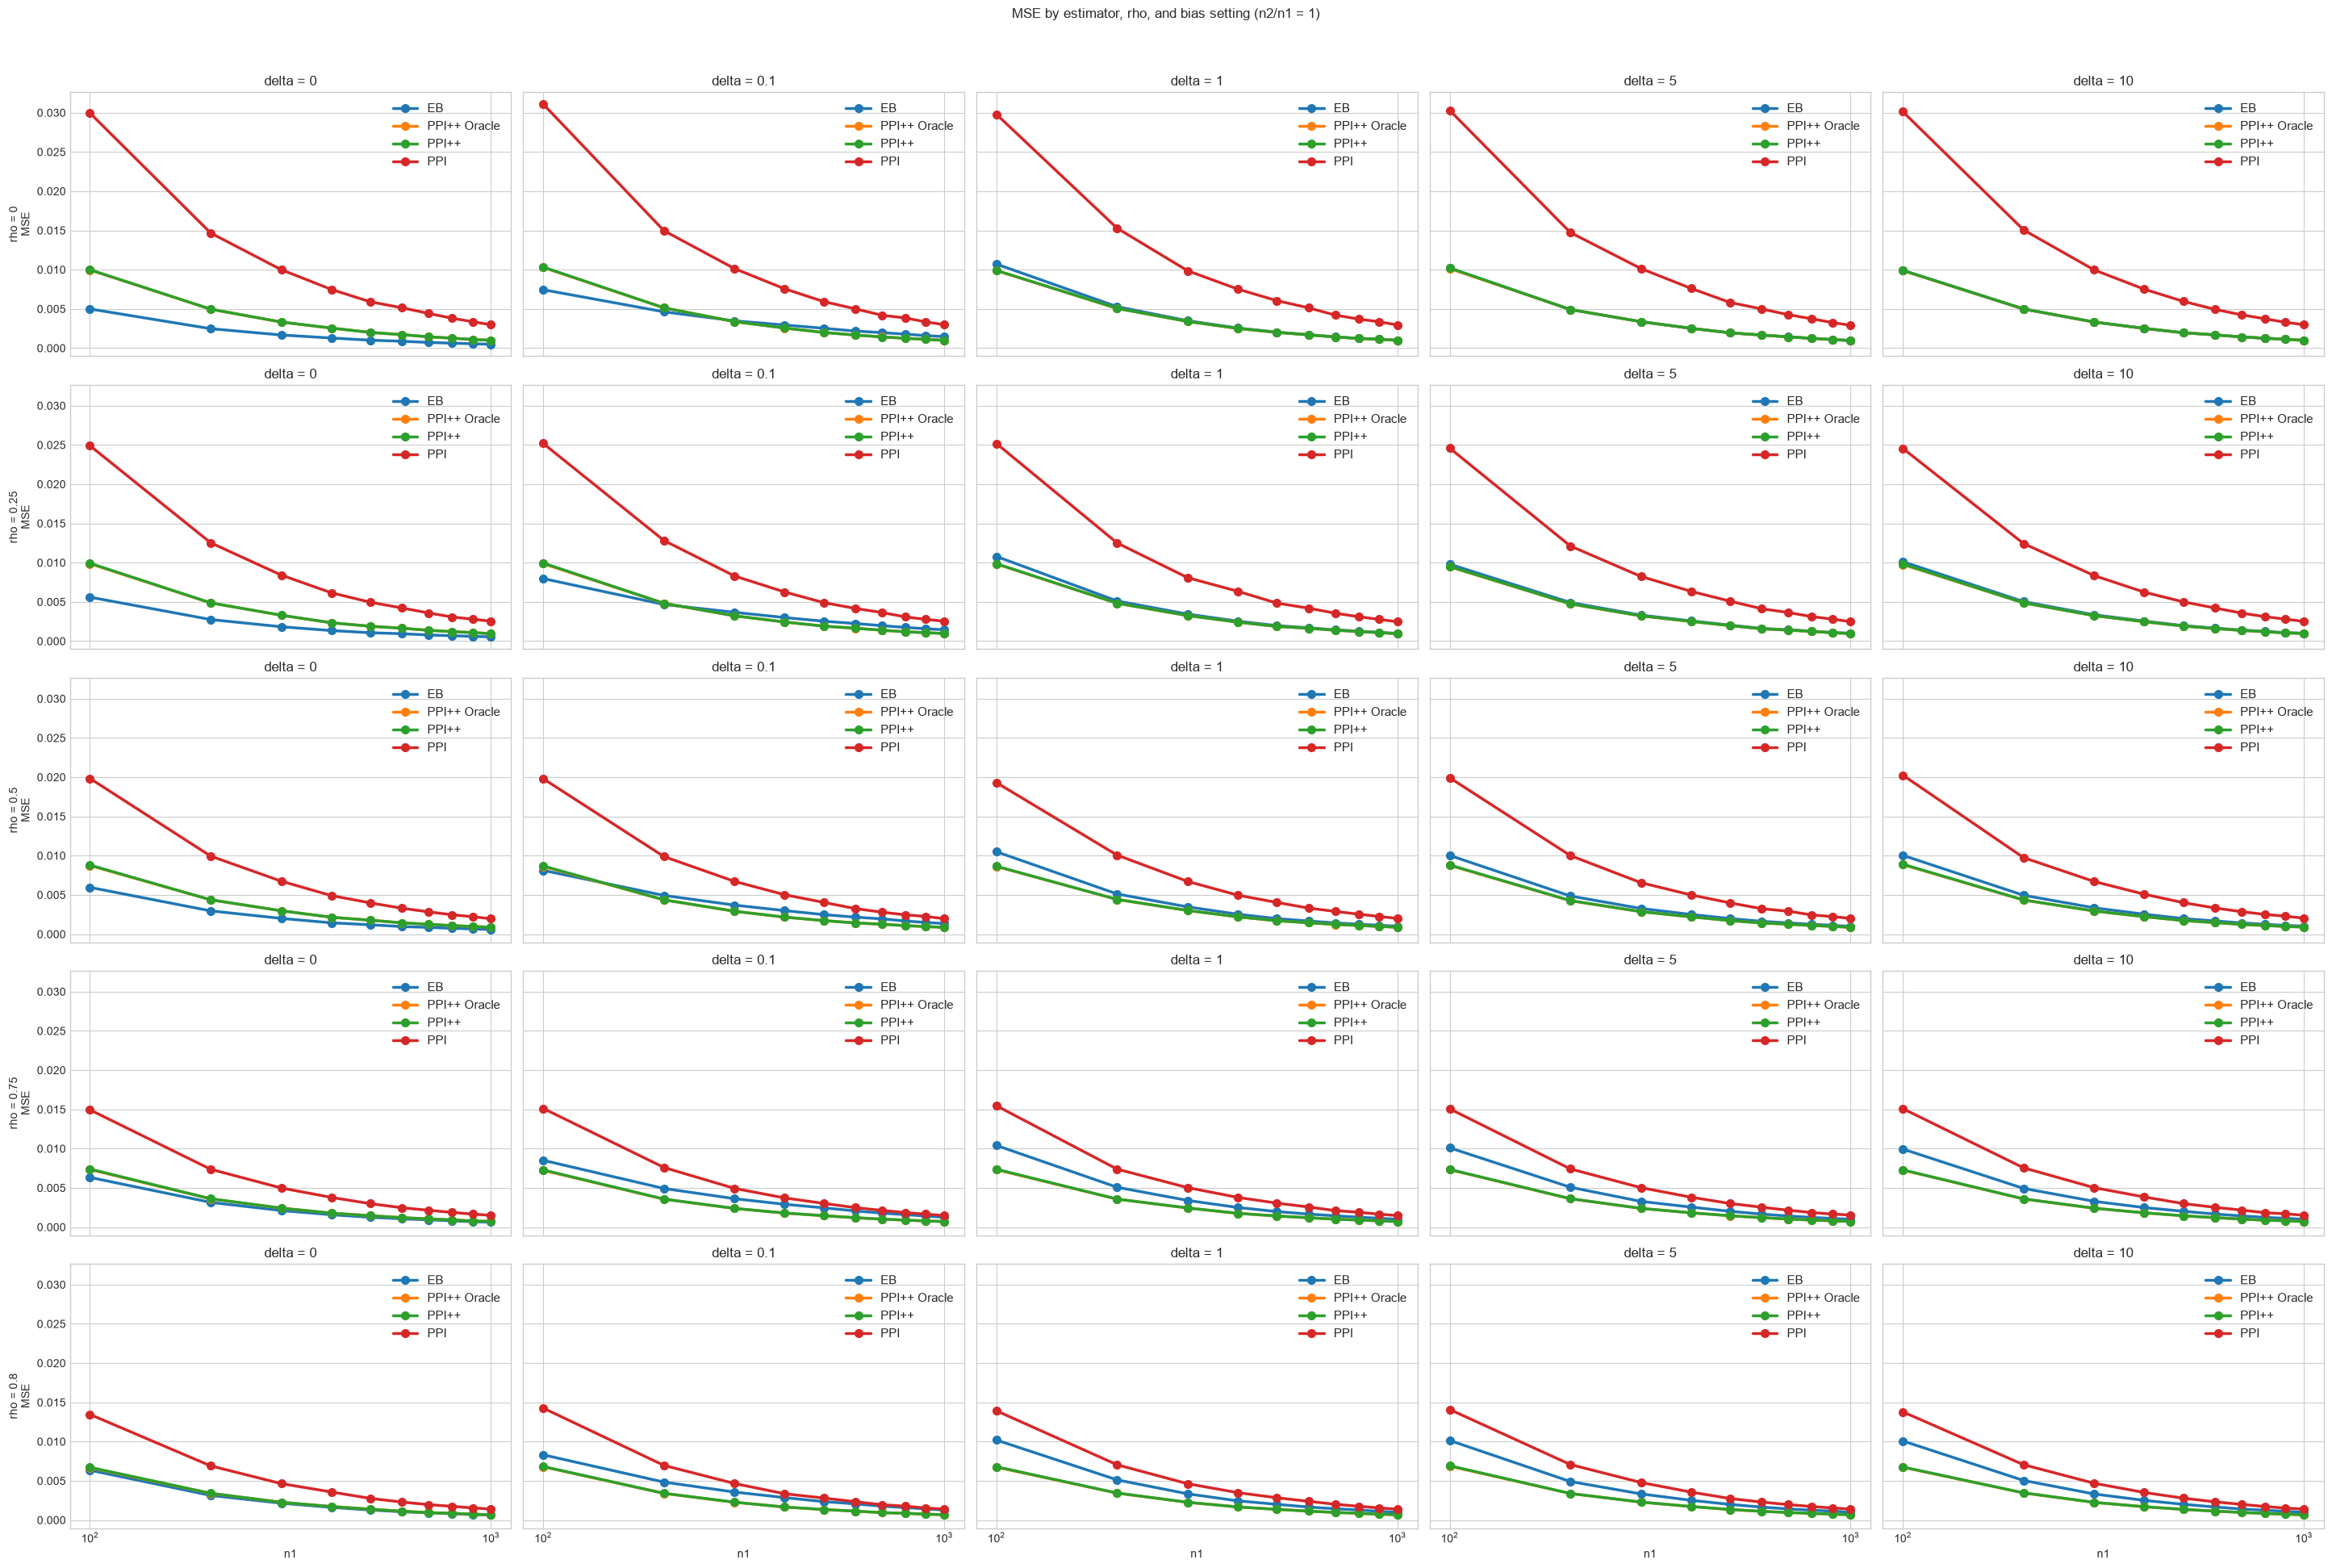

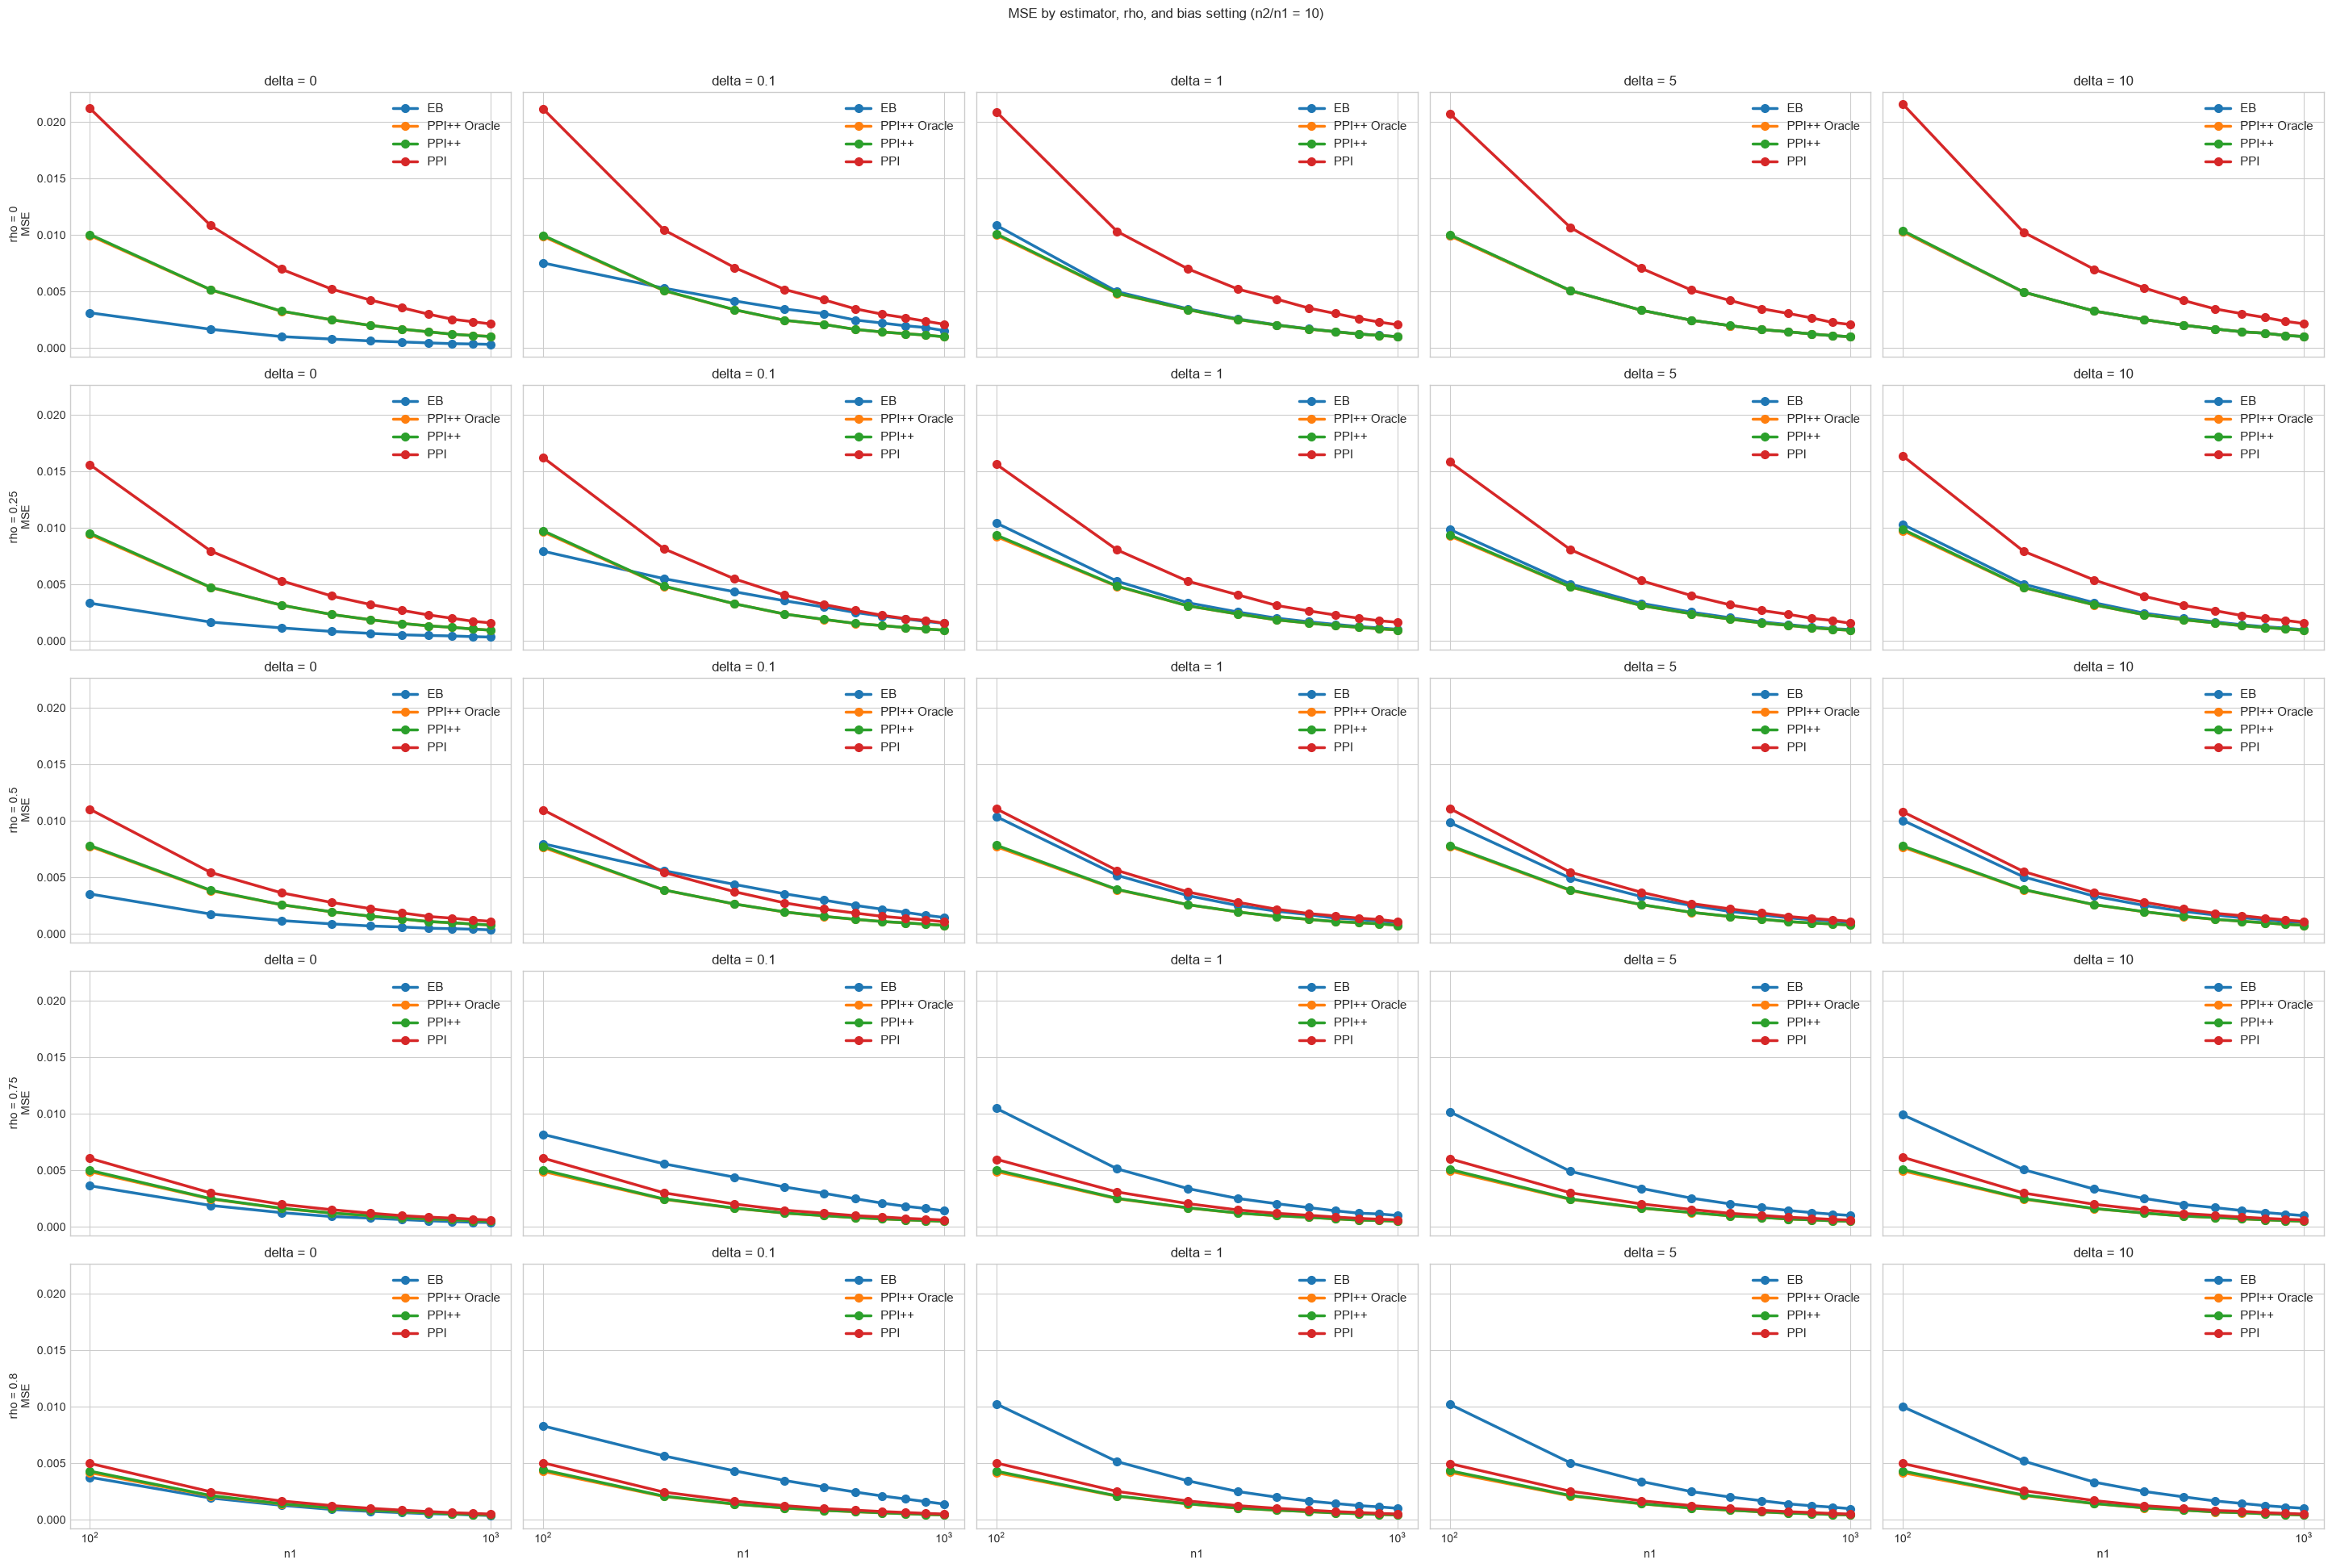

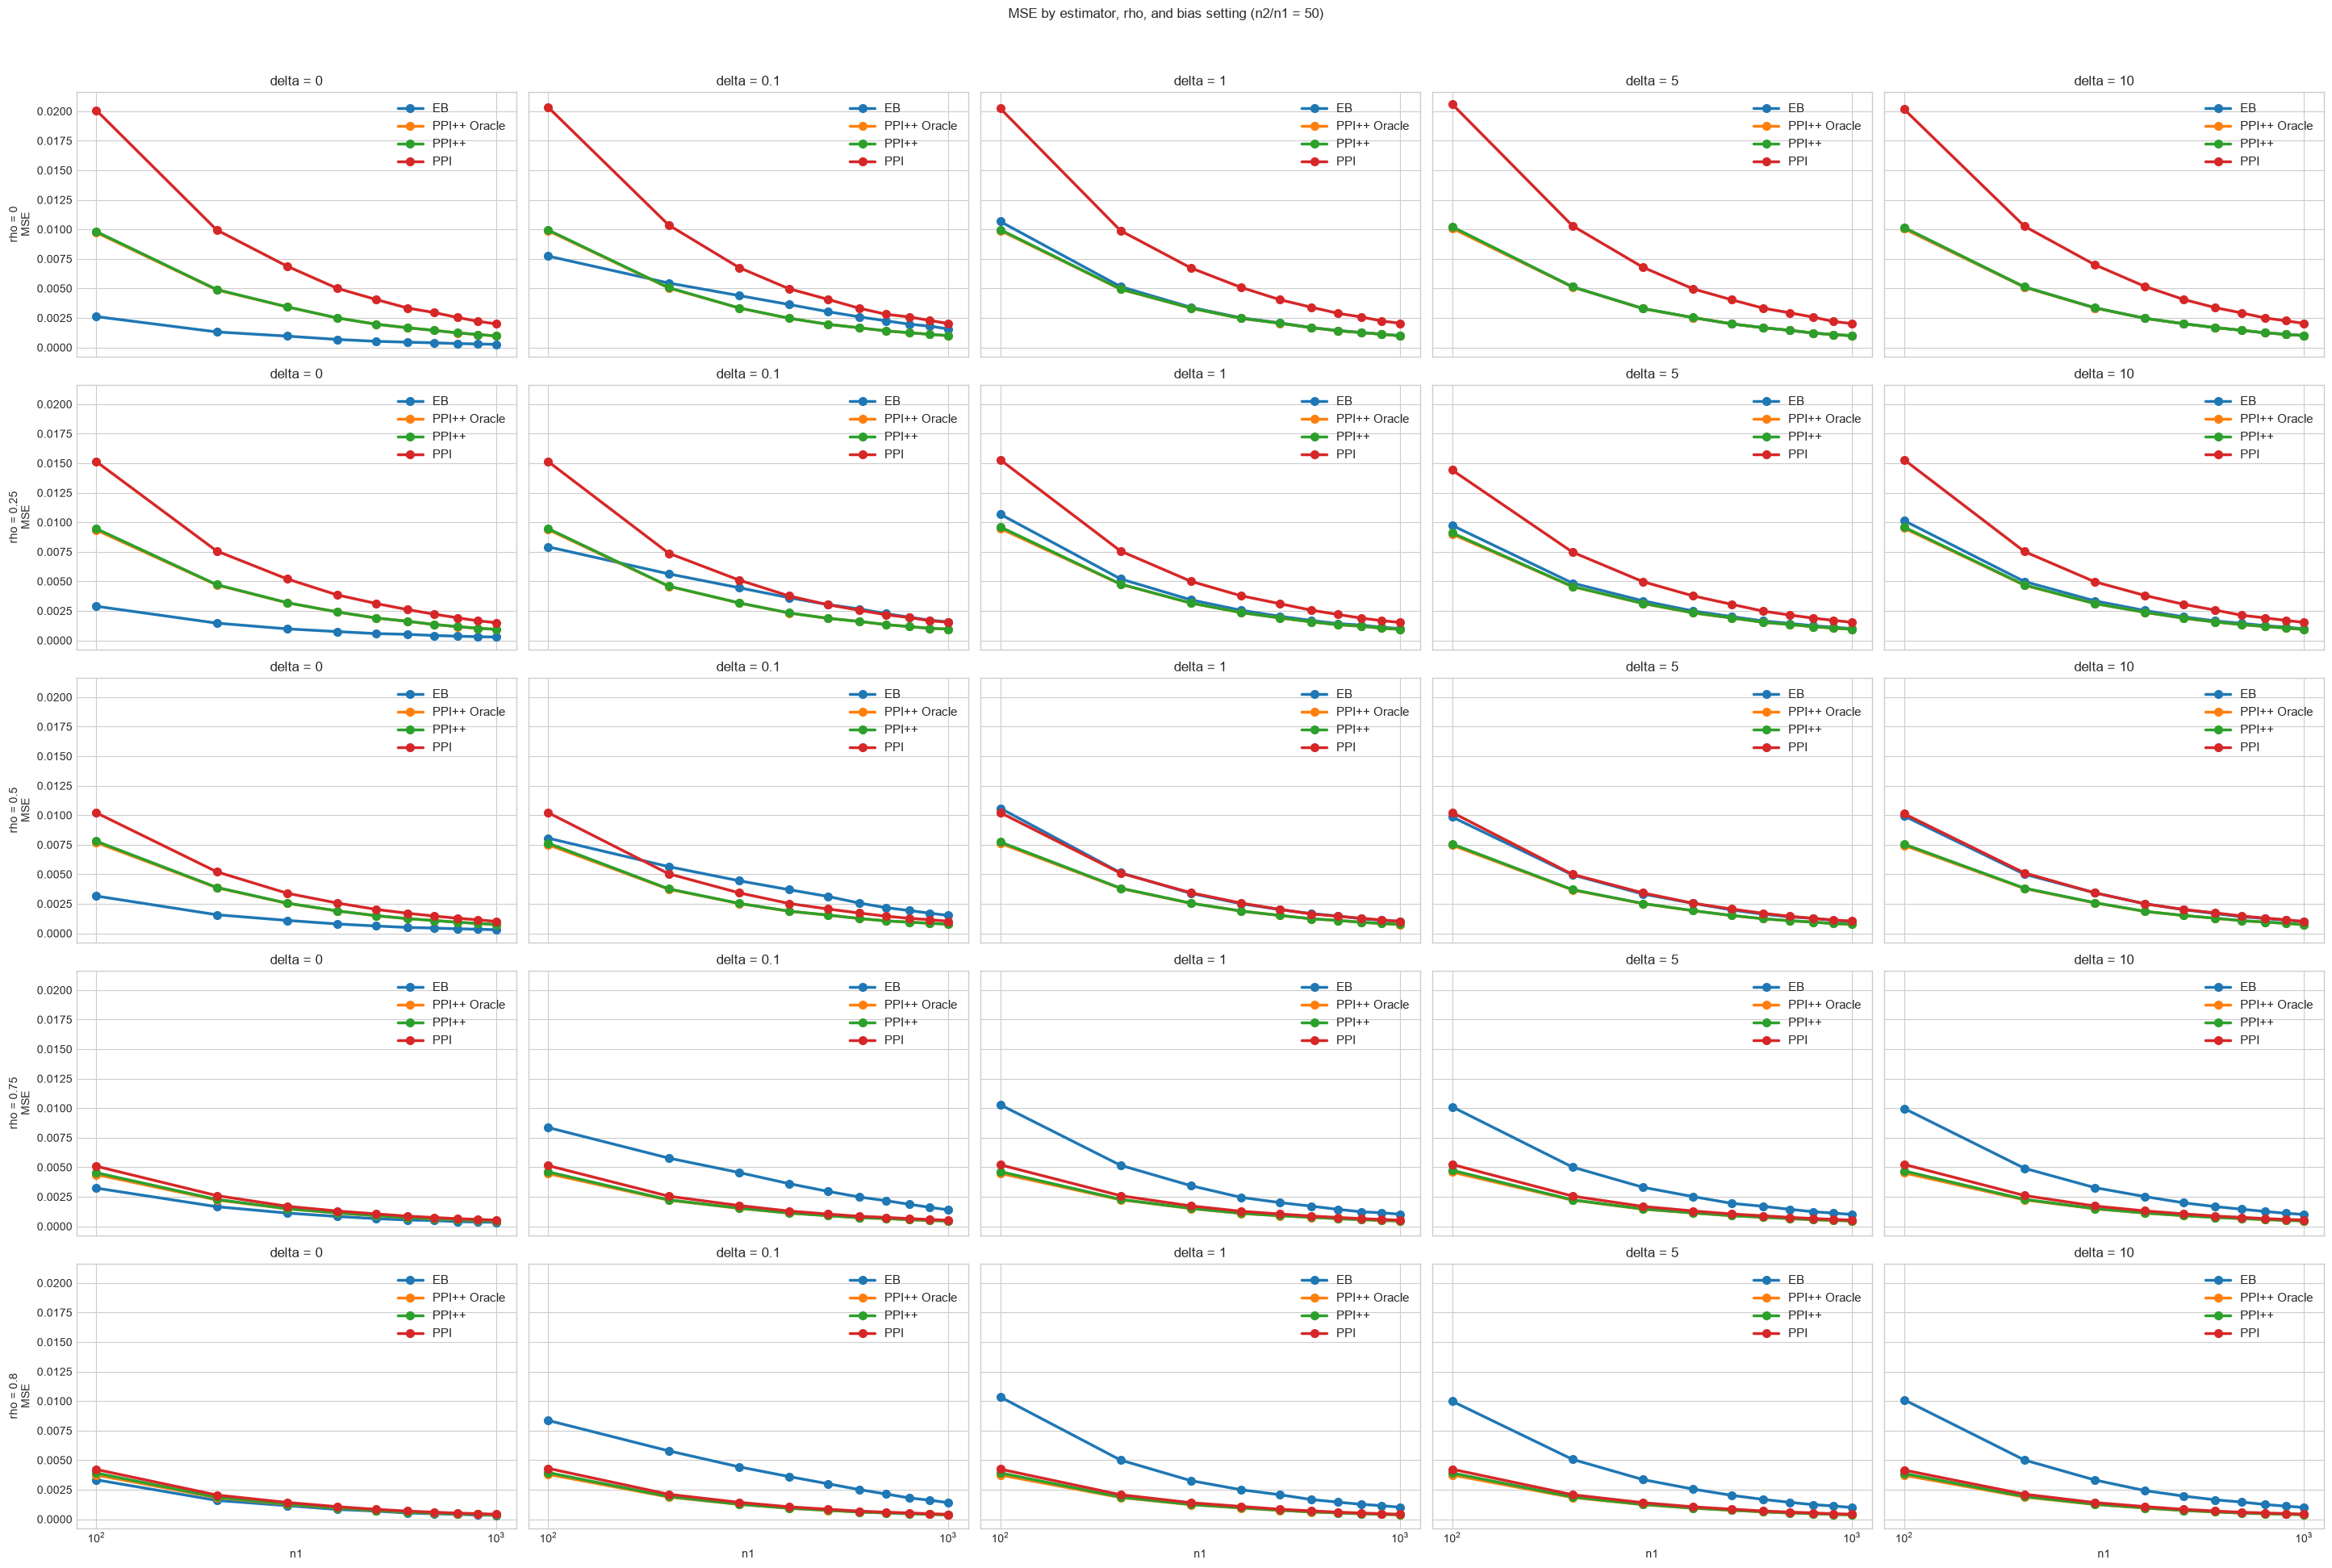

In [7]:
for multiplier in multipliers:
    selected = summary[summary['multiplier'] == multiplier]
    fig, axes = plt.subplots(
        len(rhos), len(deltas),
        figsize=(5.8 * len(deltas), 3.8 * len(rhos)),
        sharex=True, sharey=True, squeeze=False,
    )

    for row, rho in enumerate(rhos):
        for col, delta in enumerate(deltas):
            ax = axes[row, col]
            panel = selected[(selected['rho'] == rho) & (selected['delta'] == delta)]
            for method in methods:
                mse_column = f'{method}_mse'
                curve = panel.sort_values('n1')
                ax.plot(curve['n1'], curve[mse_column], marker='o',
                        linewidth=2.5, markersize=7, label=method_labels[method])
            ax.set_xscale('log')
            ax.set_title(f'delta = {delta:g}')
            if col == 0:
                ax.set_ylabel(f'rho = {rho:g}\nMSE')
            if row == len(rhos) - 1:
                ax.set_xlabel('n1')
            ax.legend(fontsize=11)

    fig.suptitle(f'MSE by estimator, rho, and bias setting (n2/n1 = {multiplier:g})', y=1.02)
    plt.tight_layout()
    plt.show()

## Plots with differing bias in $f(x)$ and $f(\tilde x)$

In [8]:
methods = ['eb', 'ppi_plus_plus_lrt']
method_labels = {'eb': 'EB', 'ppi_plus_plus_lrt': 'PPI++ LRT'}

In [ ]:
SUMMARY_PATH = Path('../data/summary_with_bias_LRT_correction.csv')

summary = pd.read_csv(SUMMARY_PATH)

# n2/n1 is the requested multiplier. Keep a rounded value for stable grouping
# when the input contains decimal sample-size multipliers.
summary['multiplier'] = (summary['n2'] / summary['n1']).round(10)

# Treat delta_f and delta_c as separate bias parameters.
delta_fs = sorted(summary['delta_f'].unique())
delta_cs = sorted(summary['delta_c'].unique())

multipliers = sorted(summary['multiplier'].unique())
rhos = sorted(summary['rho'].unique())

summary[['n1', 'n2', 'multiplier', 'delta_f', 'delta_c', 'rho']].head()
summary

,n1,n2,mu,delta_f,delta_c,rho,sigma1,sigma2,sigma3,n_replicates,...,ppi_plus_plus_bias,ppi_plus_plus_variance,ppi_plus_plus_mse,ppi_plus_plus_lrt_bias,ppi_plus_plus_lrt_variance,ppi_plus_plus_lrt_mse,ppi_plus_plus_oracle_bias,ppi_plus_plus_oracle_variance,ppi_plus_plus_oracle_mse,multiplier
0,100,100,3.0,0.0,0.0,0.00,1.0,1.0,1.0,10000,...,0.001055,0.009874,0.009874,0.001057,0.009874,0.009874,0.000909,0.009845,0.009845,1.0
1,100,100,3.0,0.0,0.0,0.25,1.0,1.0,1.0,10000,...,0.001203,0.009704,0.009705,0.001213,0.009702,0.009702,0.001097,0.009661,0.009662,1.0
2,100,100,3.0,0.0,0.0,0.50,1.0,1.0,1.0,10000,...,-0.001764,0.008831,0.008833,-0.001774,0.008851,0.008853,-0.001838,0.008775,0.008778,1.0
3,100,100,3.0,0.0,0.0,0.75,1.0,1.0,1.0,10000,...,-0.001698,0.007357,0.007359,-0.001690,0.007395,0.007397,-0.001766,0.007302,0.007304,1.0
4,100,100,3.0,0.0,0.0,0.80,1.0,1.0,1.0,10000,...,-0.001762,0.006908,0.006910,-0.001750,0.006949,0.006951,-0.001840,0.006867,0.006870,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
745,1000,50000,3.0,0.0,1.0,0.00,1.0,1.0,1.0,10000,...,0.000168,0.001939,0.001939,0.000332,0.001011,0.001011,0.000325,0.001008,0.001008,50.0
746,1000,50000,3.0,0.0,1.0,0.25,1.0,1.0,1.0,10000,...,0.239989,0.001859,0.059453,0.000285,0.000919,0.000919,0.240718,0.000912,0.058857,50.0
747,1000,50000,3.0,0.0,1.0,0.50,1.0,1.0,1.0,10000,...,0.480650,0.001926,0.232950,-0.000379,0.000792,0.000792,0.480537,0.000772,0.231688,50.0
748,1000,50000,3.0,0.0,1.0,0.75,1.0,1.0,1.0,10000,...,0.720582,0.001872,0.521110,-0.000173,0.000504,0.000504,0.721240,0.000458,0.520645,50.0


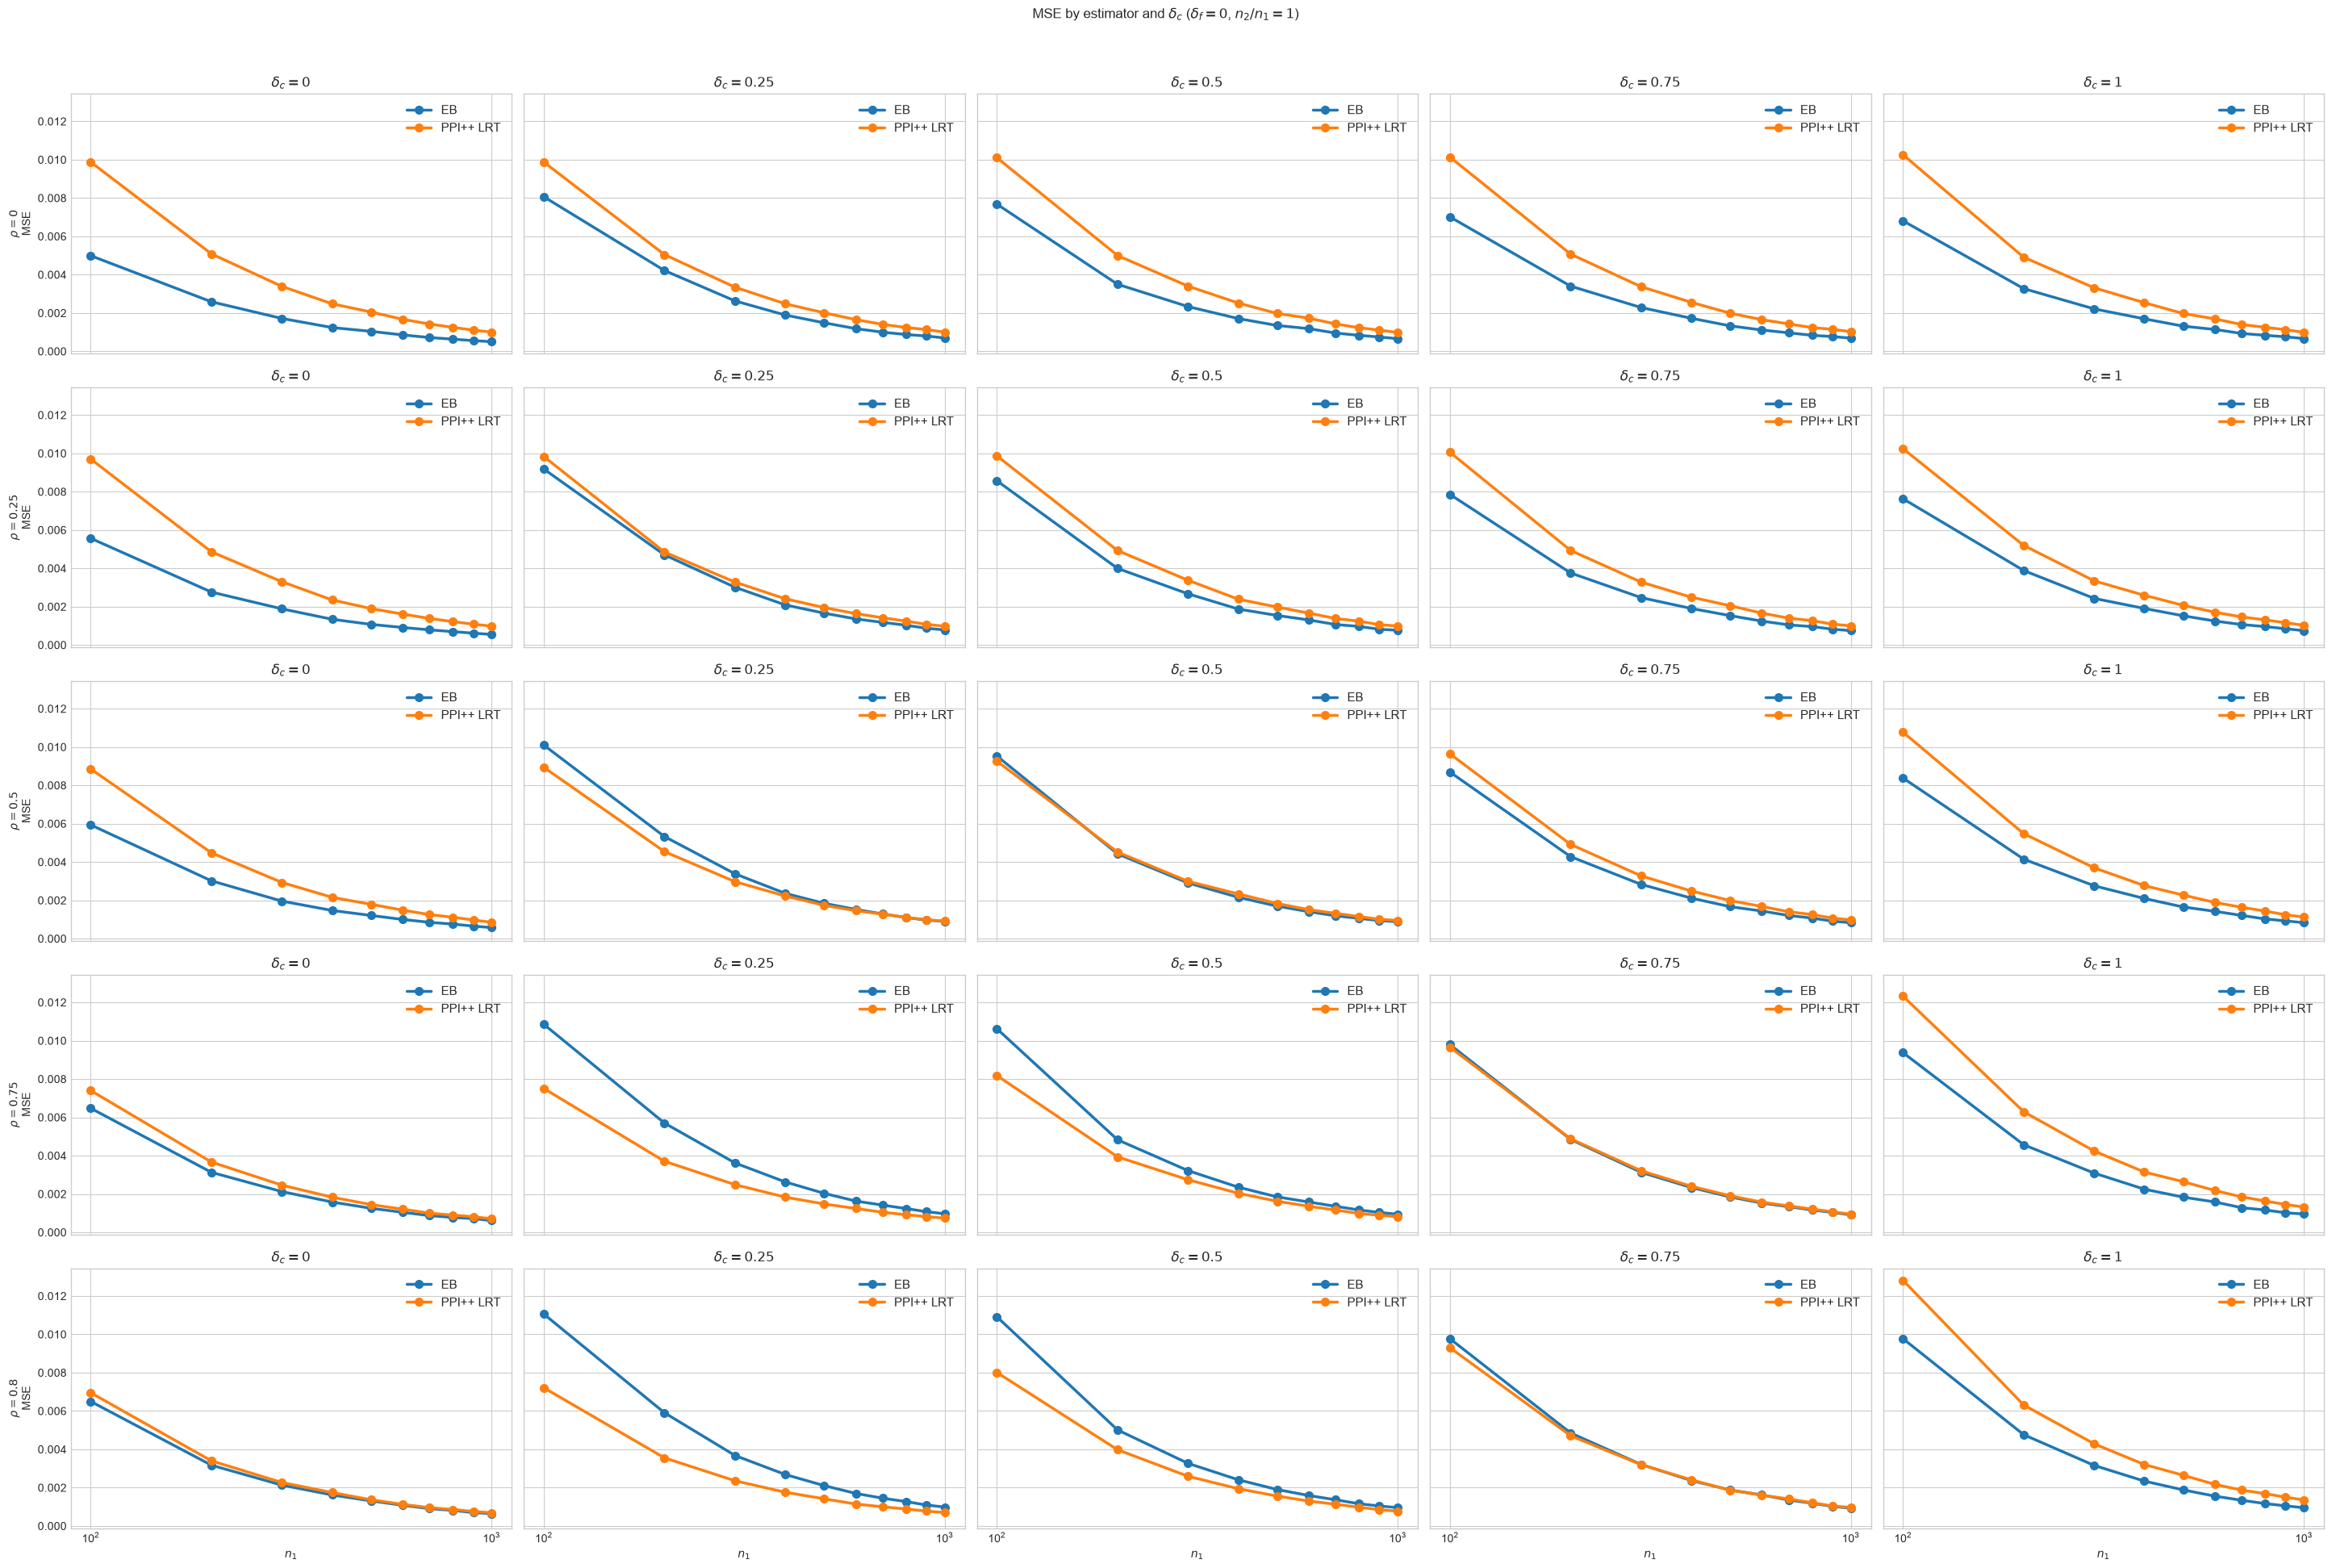

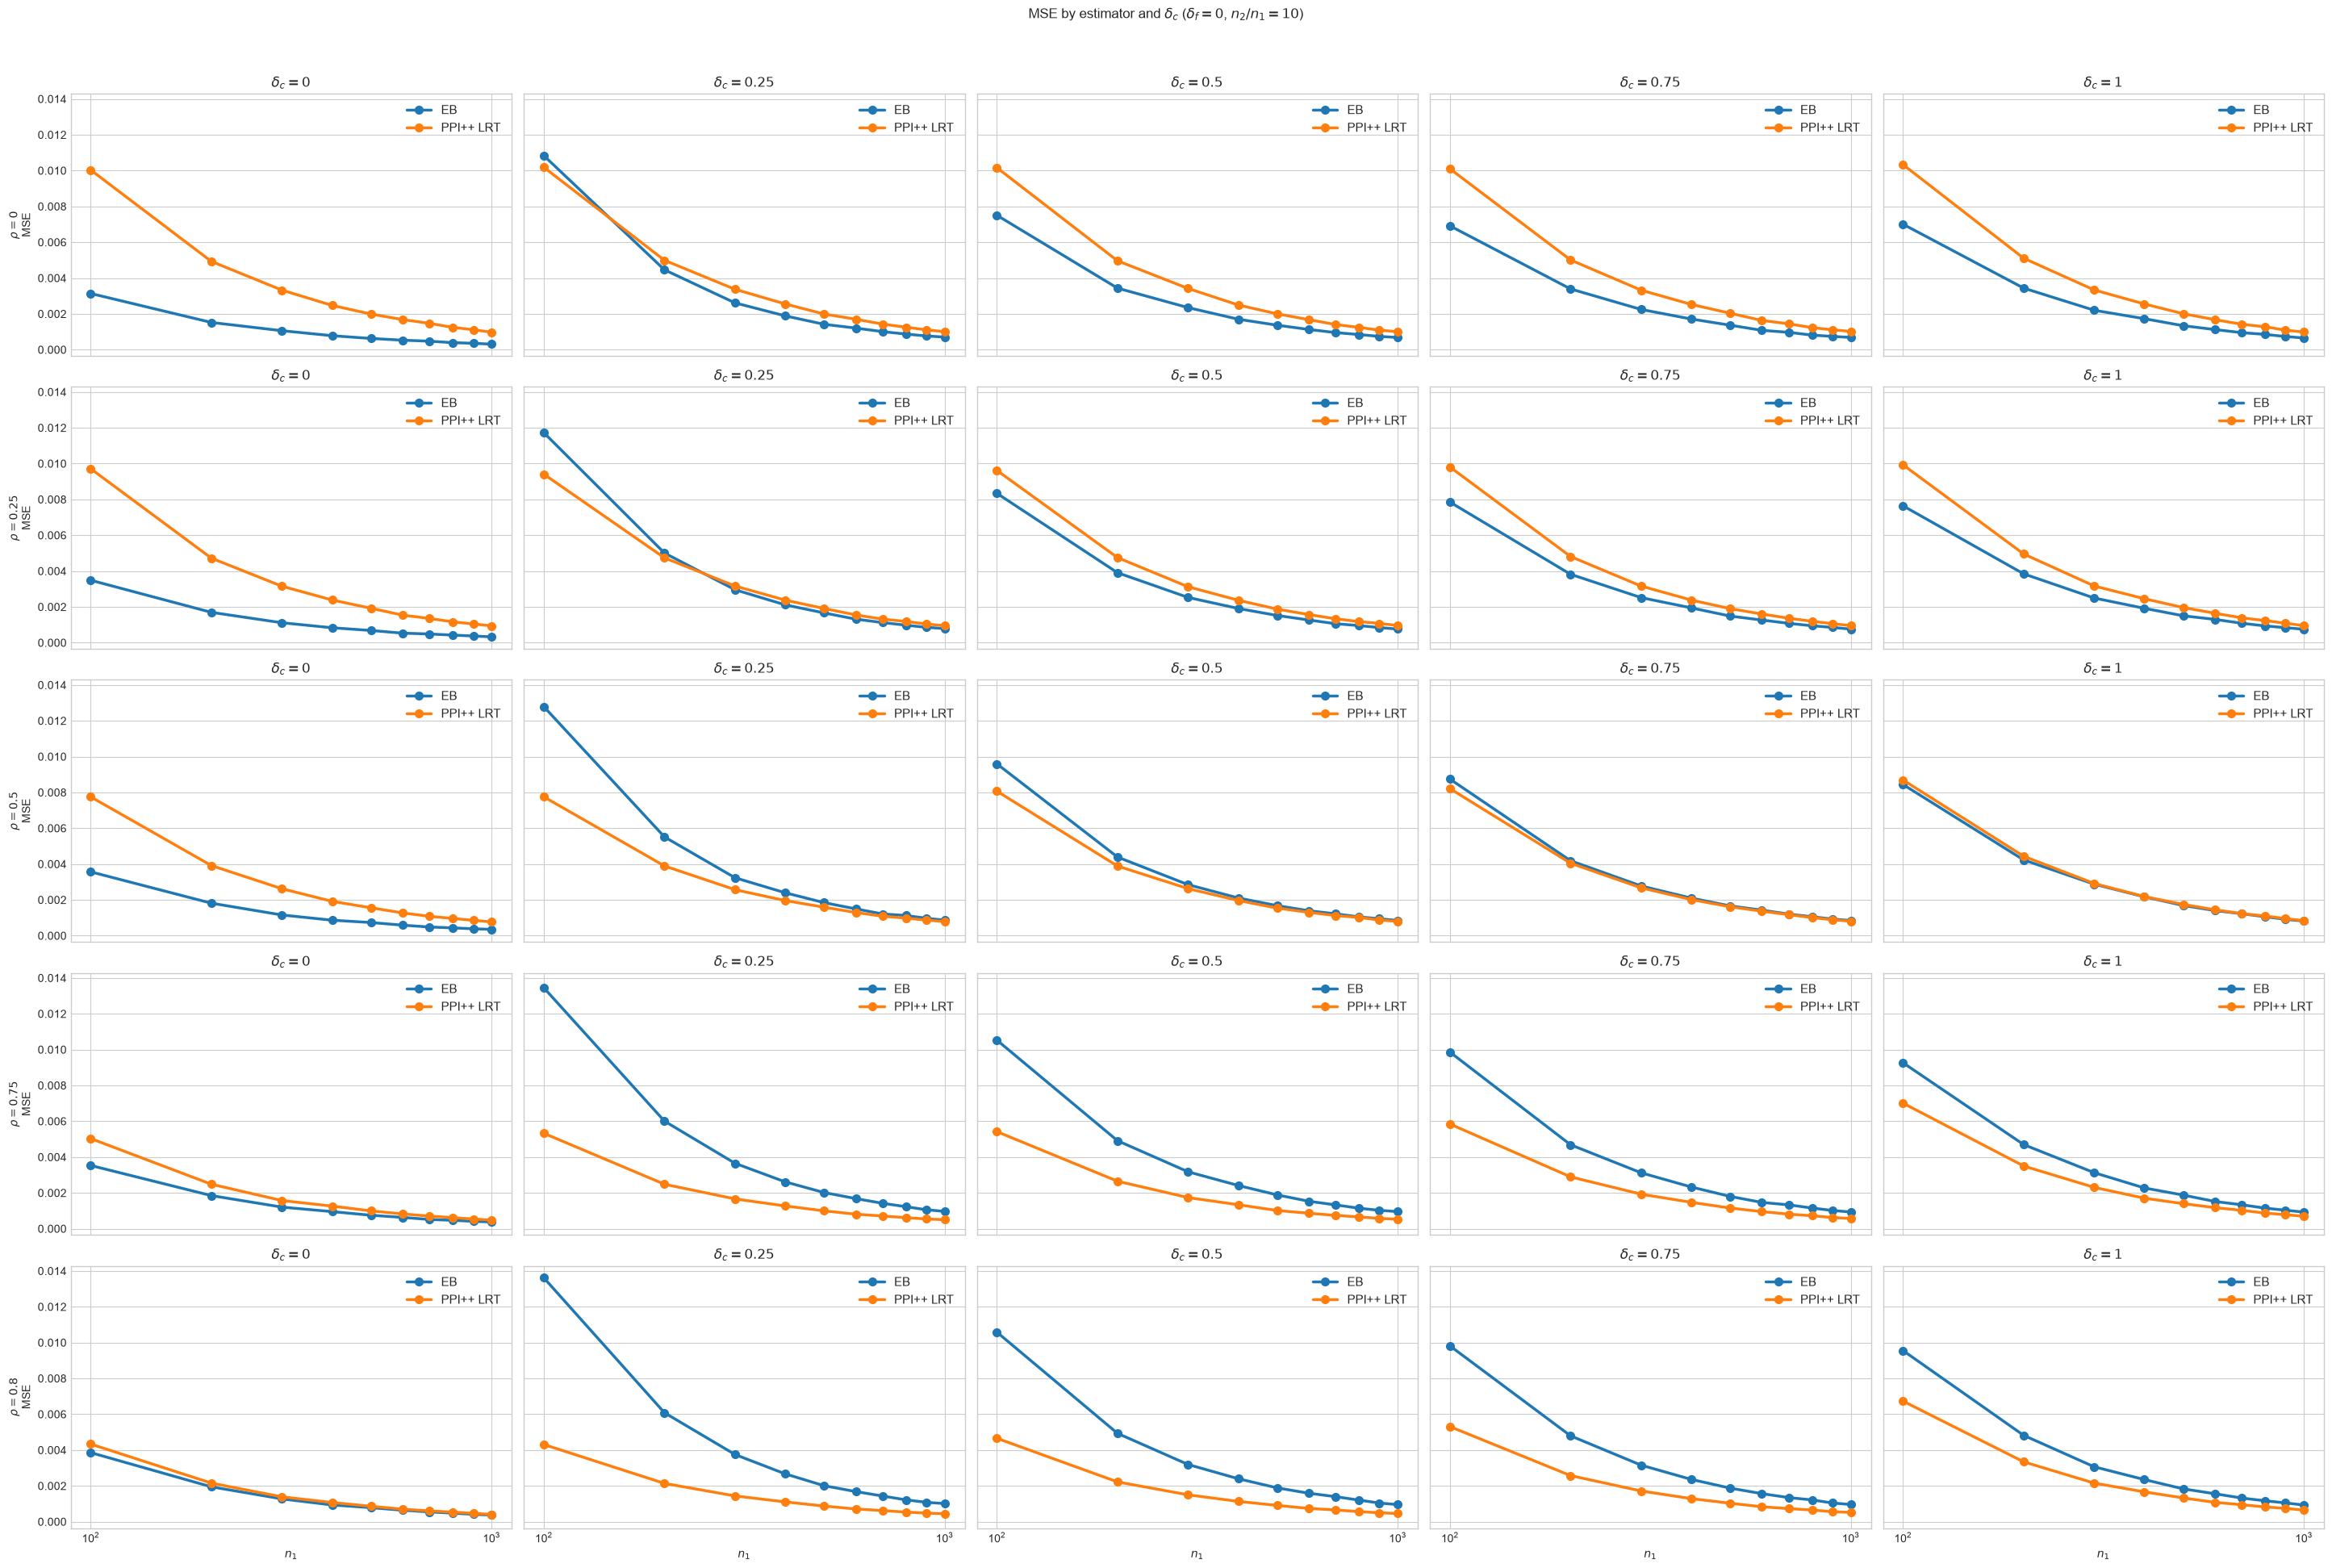

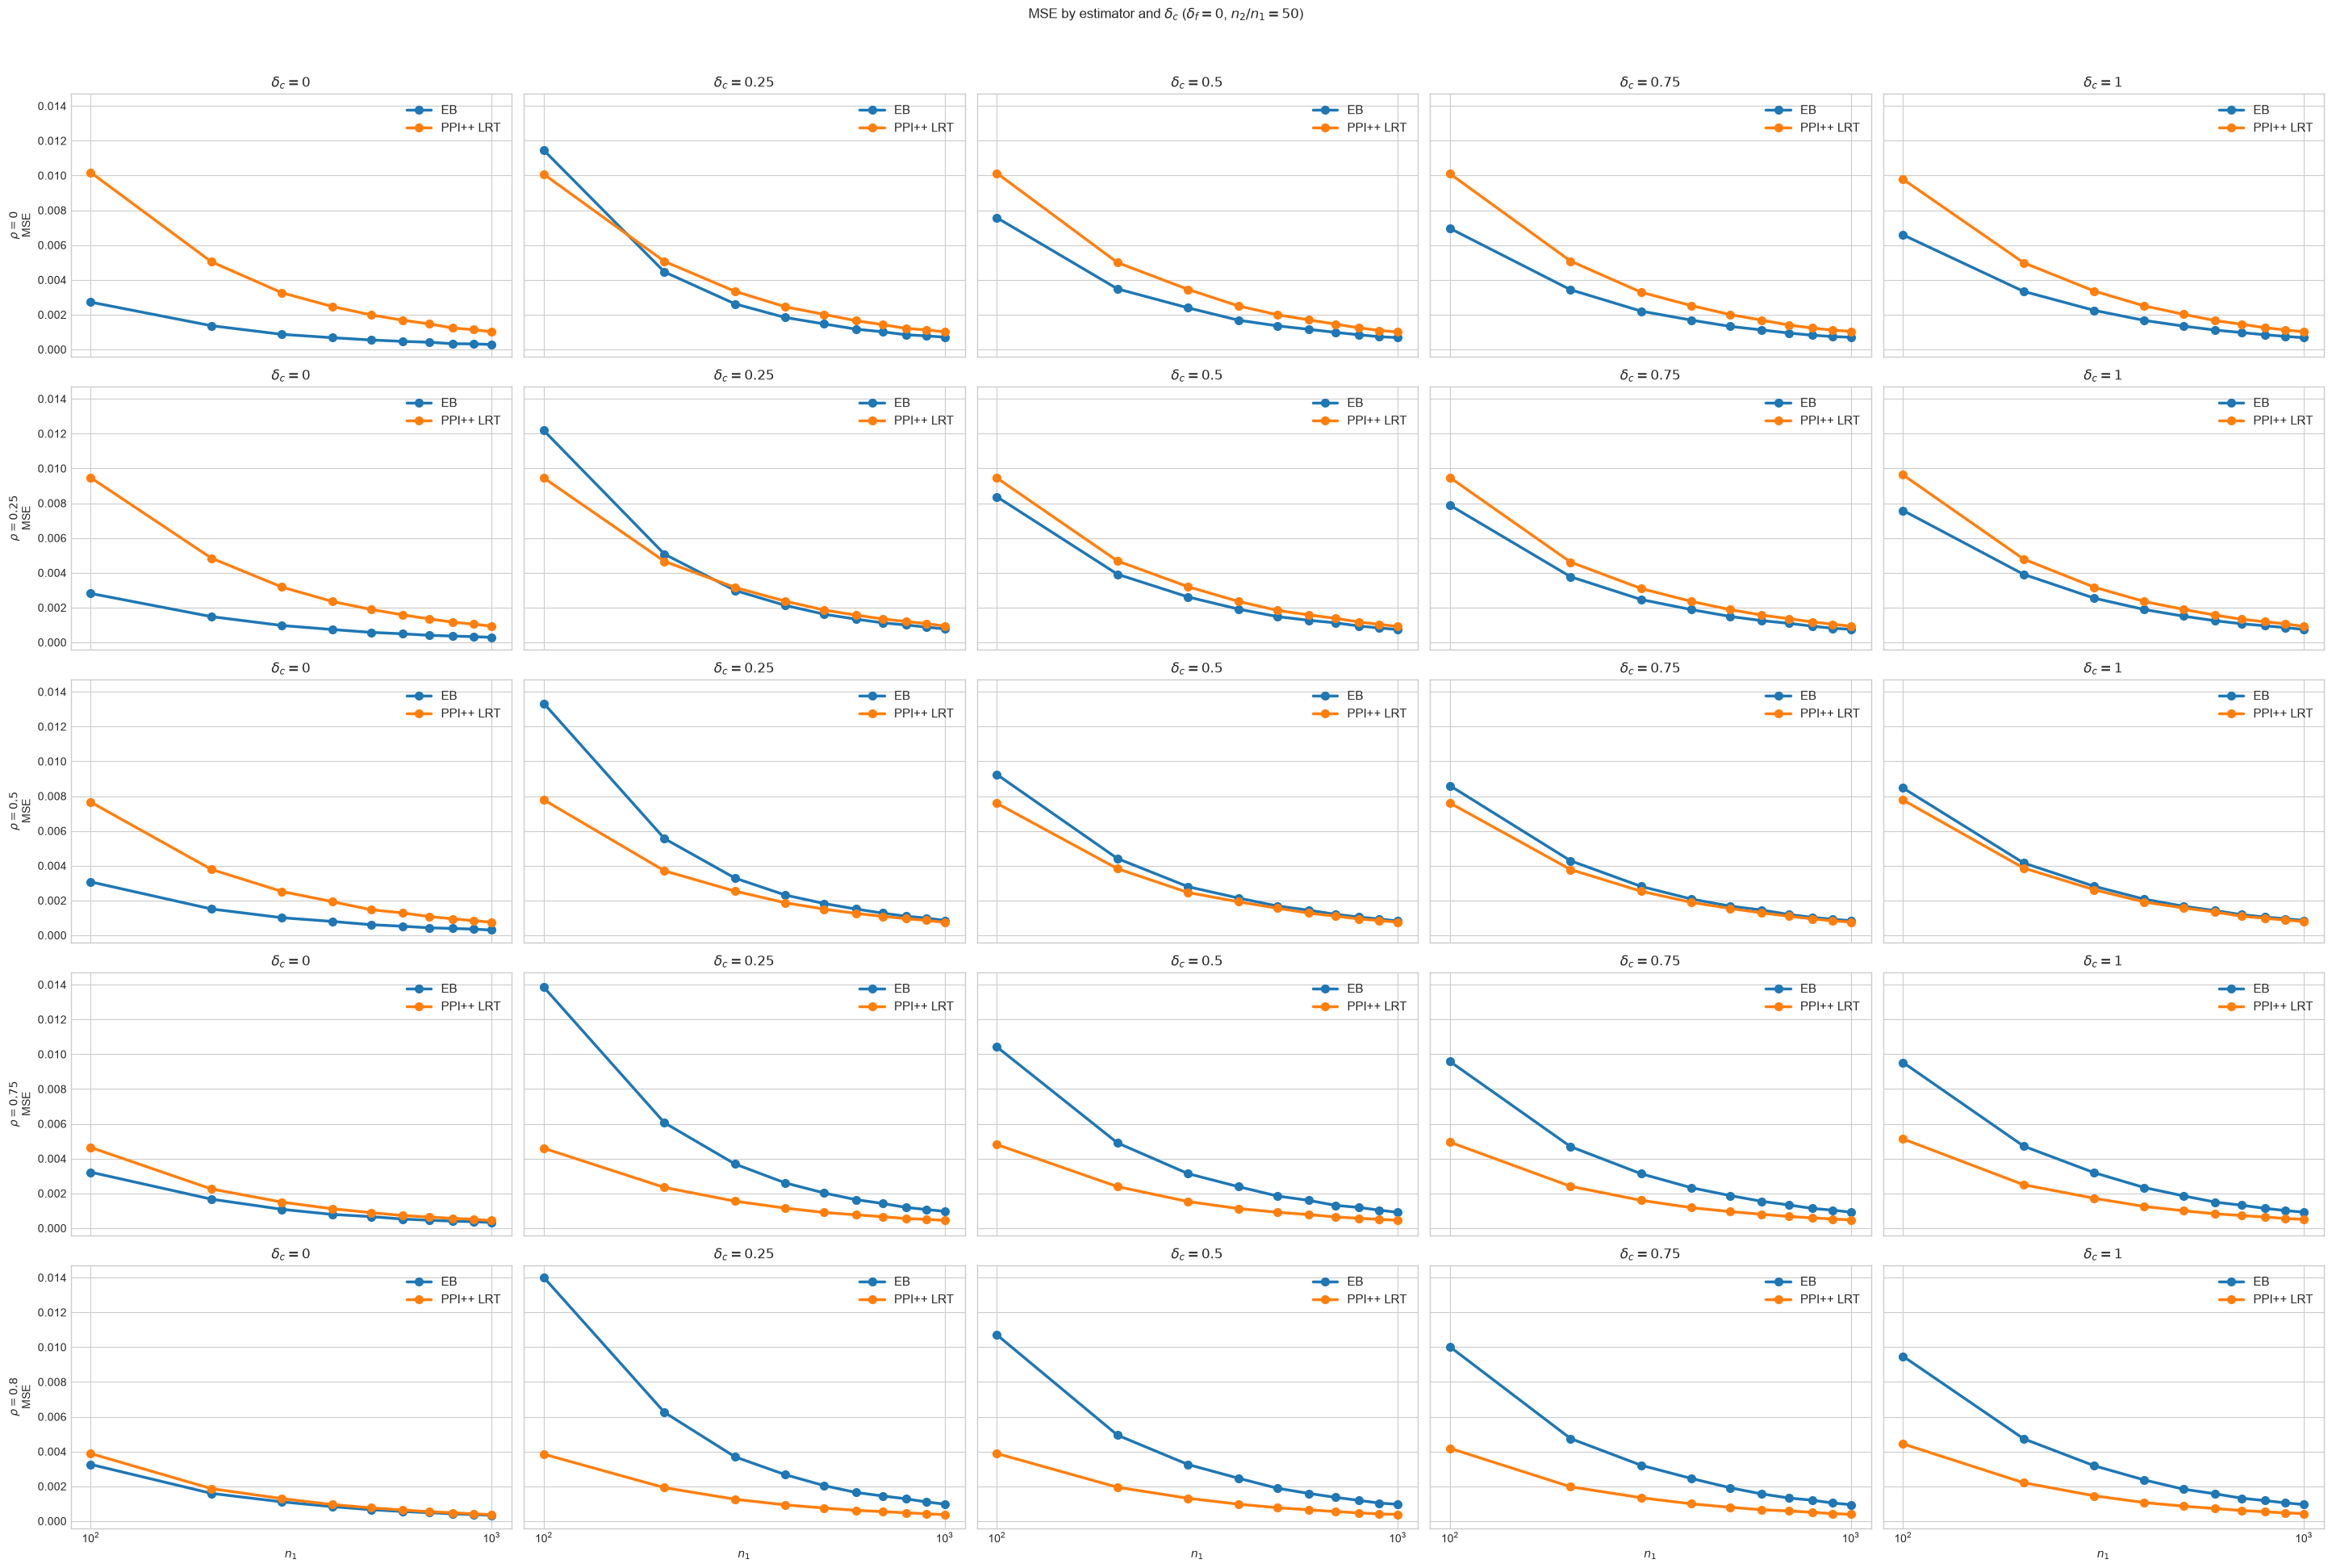

In [11]:
delta_f = summary['delta_f'].unique()[0]
delta_cs = sorted(summary['delta_c'].unique())

for multiplier in multipliers:
    selected = summary[
        (summary['multiplier'] == multiplier) &
        (summary['delta_f'] == delta_f)
    ]

    fig, axes = plt.subplots(
        len(rhos), len(delta_cs),
        figsize=(5.8 * len(delta_cs), 3.8 * len(rhos)),
        sharex=True, sharey=True, squeeze=False,
    )

    for row, rho in enumerate(rhos):
        for col, delta_c in enumerate(delta_cs):
            ax = axes[row, col]

            panel = selected[
                (selected['rho'] == rho) &
                (selected['delta_c'] == delta_c)
            ]

            curve = panel.sort_values('n1')

            for method in methods:
                mse_column = f'{method}_mse'
                ax.plot(
                    curve['n1'],
                    curve[mse_column],
                    marker='o',
                    linewidth=2.5,
                    markersize=7,
                    label=method_labels[method],
                )

            ax.set_xscale('log')
            ax.set_title(rf'$\delta_c = {delta_c:g}$')

            if col == 0:
                ax.set_ylabel(rf'$\rho = {rho:g}$' + '\nMSE')

            if row == len(rhos) - 1:
                ax.set_xlabel(r'$n_1$')

            ax.legend(fontsize=11)

    fig.suptitle(
        rf'MSE by estimator and $\delta_c$ '
        rf'($\delta_f = {delta_f:g}$, $n_2/n_1 = {multiplier:g}$)',
        y=1.02,
    )

    plt.tight_layout()
    plt.show()

## Two-estimator comparisons

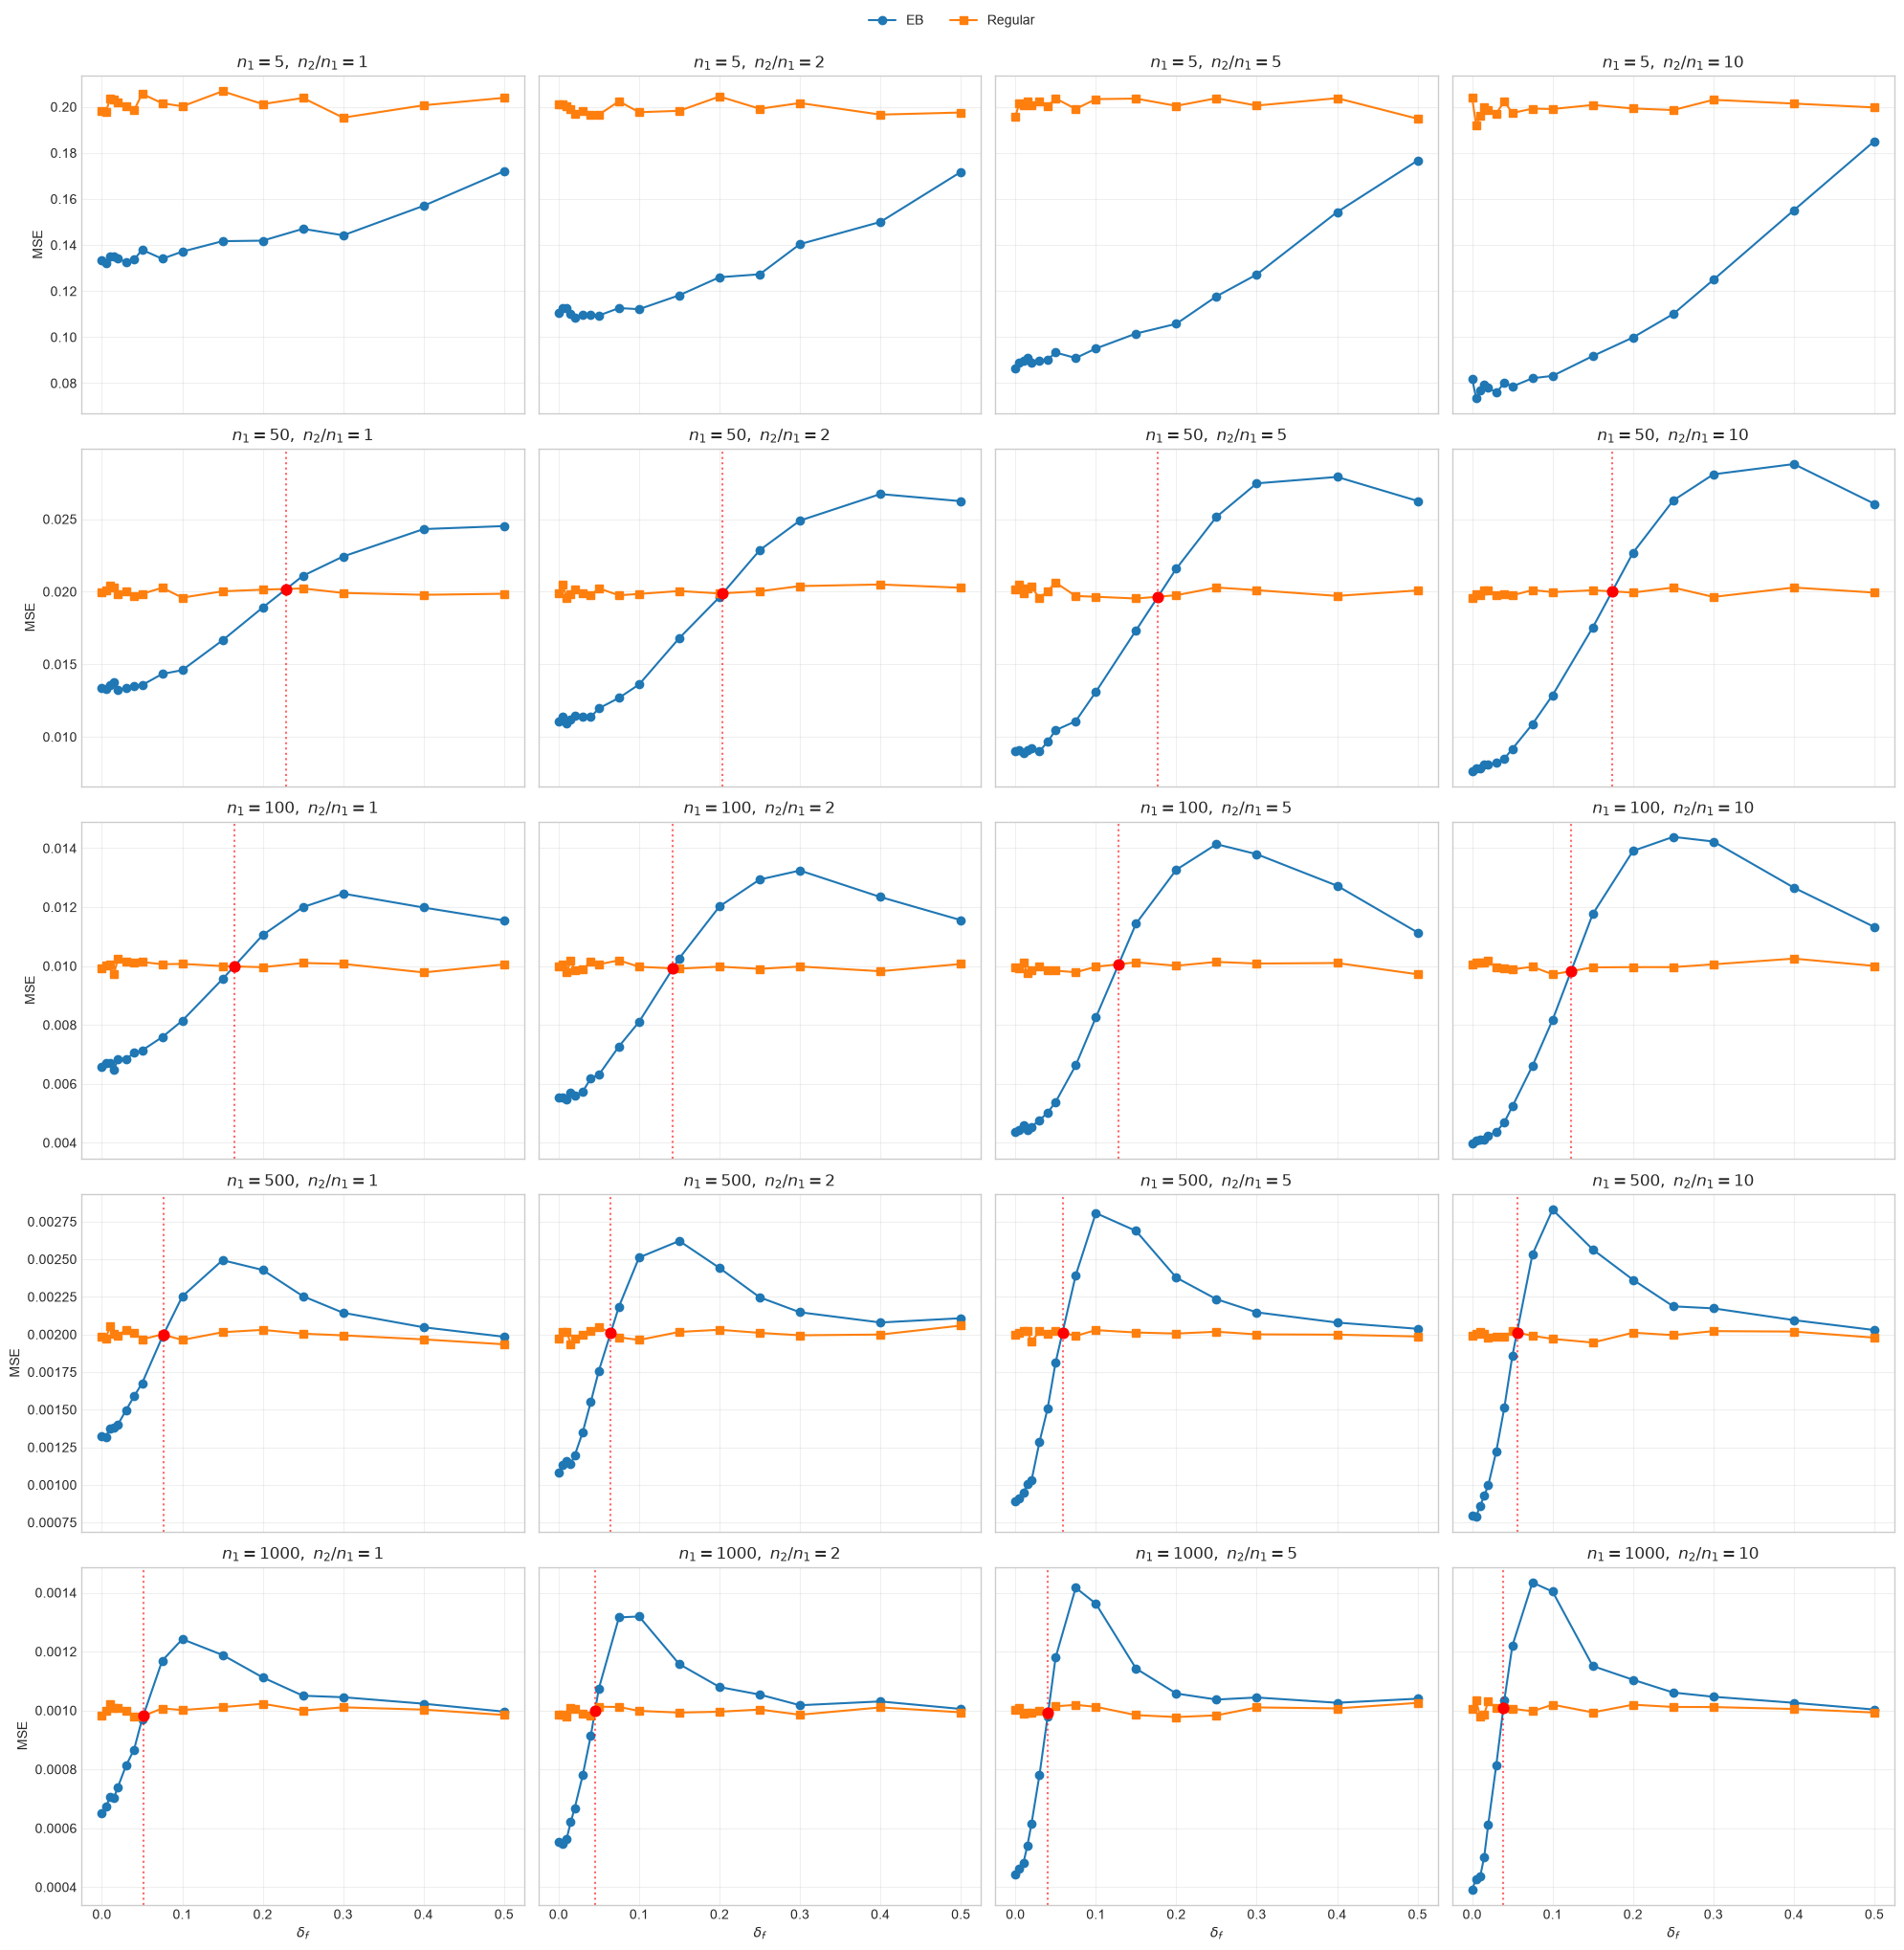

  n1  multiplier              crossings
   5         1.0                     []
   5         2.0                     []
   5         5.0                     []
   5        10.0                     []
  50         1.0  [0.22927222258824537]
  50         2.0  [0.20411145894217345]
  50         5.0  [0.17729371563723517]
  50        10.0  [0.17413720855809972]
 100         1.0  [0.16440528281639702]
 100         2.0   [0.1421211662735846]
 100         5.0  [0.12837427783627103]
 100        10.0  [0.12302721897859945]
 500         1.0  [0.07648157468263193]
 500         2.0  [0.06470133324435165]
 500         5.0    [0.058601605099183]
 500        10.0  [0.05577811395260707]
1000         1.0 [0.051335012100928855]
1000         2.0 [0.045211479959863694]
1000         5.0 [0.040660822935120876]
1000        10.0  [0.03888656674686368]


In [ ]:
summary = pd.read_parquet("../data/summary_results_two_estimator.parquet")
summary["multiplier"] = summary["n2"] / summary["n1"]

n1_values = sorted(summary["n1"].unique())
multipliers = sorted(summary["multiplier"].unique())

fig, axes = plt.subplots(
    len(n1_values),
    len(multipliers),
    figsize=(5 * len(multipliers), 4 * len(n1_values)),
    squeeze=False,
    sharex=True,
    sharey="row",
)

crossing_results = []

for i, n1 in enumerate(n1_values):
    for j, multiplier in enumerate(multipliers):
        ax = axes[i, j]

        subset = summary[
            (summary["n1"] == n1)
            & np.isclose(summary["multiplier"], multiplier)
        ].sort_values("delta_f")

        delta = subset["delta_f"].to_numpy()
        mse_eb = subset["mse_eb"].to_numpy()
        mse_regular = subset["mse_regular"].to_numpy()

        ax.plot(delta, mse_eb, marker="o", label="EB")
        ax.plot(delta, mse_regular, marker="s", label="Regular")

        # Find crossings by linear interpolation.
        diff = mse_eb - mse_regular
        crossings = []

        for k in range(len(delta) - 1):
            if diff[k] * diff[k + 1] < 0:
                delta_cross = (
                    delta[k]
                    - diff[k] * (delta[k + 1] - delta[k])
                    / (diff[k + 1] - diff[k])
                )
                crossings.append(delta_cross)

                mse_cross = np.interp(delta_cross, delta, mse_eb)

                ax.scatter(
                    delta_cross, mse_cross,
                    color="red", s=60, zorder=5
                )
                ax.axvline(
                    delta_cross, color="red",
                    linestyle=":", alpha=0.6
                )

        crossing_results.append({
            "n1": n1,
            "multiplier": multiplier,
            "crossings": crossings,
        })

        ax.set_title(rf"$n_1={n1},\ n_2/n_1={multiplier:g}$")
        ax.grid(alpha=0.3)

        if i == len(n1_values) - 1:
            ax.set_xlabel(r"$\delta_f$")

        if j == 0:
            ax.set_ylabel("MSE")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 1.02),
)

plt.tight_layout()
plt.show()

crossing_df = pd.DataFrame(crossing_results)
print(crossing_df.to_string(index=False))
